# E2 Frozen Whisper + Logistic Regression

Does a frozen speech encoder provide useful features without accent fine-tuning?

This run uses the existing 2,000 audio clips. Label 1 is MNSC / Singapore.
Label 0 is Common Voice / non-Singapore. Corpus and class are linked.
High scores do not establish accent recognition under new recording conditions.

All six matched notebooks use one saved clip list and one speaker split.
Training and validation select settings. Test speakers measure the fixed model.
The first grouped fold supplies test data. This is **one split**, not full cross-validation.

Shared implementation: [experiment_common.py](experiment_common.py).
Read its audio and evaluation functions to inspect the full procedure.
The original notebooks were backed up before this update.

## 1. Use the local audio environment

Use the **Singlish audio review (Python 3.12)** kernel.
Dependencies are already installed. This notebook does not upgrade packages.
Set the two paths below if the project moves.

In [1]:
from pathlib import Path
import sys

USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Singlish')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'audio'
else:
    PROJECT_ROOT = Path('/home/mh/nusproj/singlish-whisper')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'e1_audio_1000x2' / 'data'

sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import experiment_common as common
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

%matplotlib inline
config = common.configure(PROJECT_ROOT, DATA_ROOT)
print('Audio:', DATA_ROOT)
print('Results:', config['output'])
print(json.dumps(common.environment(), indent=2))

Audio: /home/mh/nusproj/singlish-whisper/data/e1_audio_1000x2/data
Results: /home/mh/nusproj/singlish-whisper/outputs/matched_2000_seed42
{
  "python": "3.14.7",
  "packages": {
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "librosa": "1.0.0",
    "torch": "2.14.0",
    "transformers": "4.57.6",
    "nbclient": "0.11.0"
  }
}


## 2. Verify clips and load the shared split

File hashes detect duplicate audio. Extraction failures stop the run.
No notebook silently drops clips or creates a different test set.
Each speaker stays in one partition. The split is approximately 64% / 16% / 20%.
The saved split remains fixed on later runs.

In [2]:
frame, fingerprint = common.prepare_manifest(config)
split = common.shared_split(config, frame, fingerprint)
y = frame.label.to_numpy()
groups = frame.group.to_numpy(dtype=str)
train_idx, val_idx, test_idx = (split[name] for name in ['train', 'validation', 'test'])
trainval_idx = np.sort(np.r_[train_idx, val_idx])
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(groups[val_idx]).isdisjoint(groups[test_idx])

Clips: {0: 1000, 1: 1000}
Speakers: {0: 300, 1: 583}
Dataset SHA256: 872f8ffa700bb810105b9796d6c0032c6d8c07bd9b3ffedfb6239a179d6fa8cb
{
  "train": {
    "clips": 1280,
    "speakers": 566,
    "label_counts": {
      "0": 640,
      "1": 640
    }
  },
  "validation": {
    "clips": 320,
    "speakers": 141,
    "label_counts": {
      "0": 160,
      "1": 160
    }
  },
  "test": {
    "clips": 400,
    "speakers": 176,
    "label_counts": {
      "0": 200,
      "1": 200
    }
  }
}
Speaker overlap: 0. This is one fixed grouped split, not five-fold evaluation.


## 3. Load the frozen Whisper representations

Use `openai/whisper-base.en` in all six matched notebooks.
This is a new comparison. It differs from the older `whisper-small` script results.
The encoder weights stay fixed. Only the logistic-regression head learns class labels.
We average encoder steps that correspond to real, trimmed audio.
The 30-second padded tail is excluded from this average.
All methods receive the same prepared waveform and clip order.

In [3]:
A, X = common.load_features(config, frame, fingerprint, whisper=True)

Acoustic features: (2000, 39)
Whisper features: (2000, 512)


## 4. Select classifier regularization on validation speakers

The full 512-dimensional embedding is used here. No PCA is applied.
The scaler learns from training speakers only. Validation macro F1 selects C.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

candidates = [(f'C={c:g}', Pipeline([
    ('scale', StandardScaler()),
    ('classifier', LogisticRegression(C=c, class_weight='balanced', max_iter=5000,
                                     random_state=common.SEED)),
])) for c in [0.01, 0.1, 1.0, 10.0, 100.0]]
selected_model, validation = common.choose_candidate(candidates, X, y, split)

candidate  macro_f1  balanced_accuracy
   C=0.01  0.962499           0.962500
    C=0.1  0.953114           0.953125
      C=1  0.956243           0.956250
     C=10  0.940597           0.940625
    C=100  0.931226           0.931250
Validation choice: C=0.01


## 5. Refit the head and evaluate test speakers

Keep C fixed. Refit the scaler and classifier on training plus validation speakers.
Whisper remains frozen. Scores use the same threshold as `model.predict()`.
The saved CSV retains every test clip, speaker, prediction, and score.

{
  "accuracy": 0.9825,
  "macro_f1": 0.9824998906243163,
  "balanced_accuracy": 0.9824999999999999,
  "roc_auc": 0.99785,
  "errors": 7,
  "confusion_matrix": [
    [
      196,
      4
    ],
    [
      3,
      197
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.01893358863890171,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.9659077050997783,
      0.9950983388465411
    ],
    "balanced_accuracy": [
      0.9658701939940278,
      0.9950985905681276
    ],
    "macro_f1": [
      0.9658526834491921,
      0.9950764856142932
    ]
  }
}


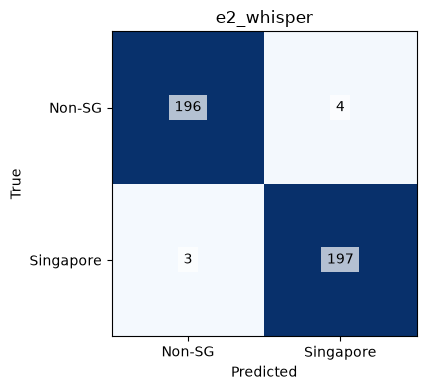

,clip_id,path,group,label,prediction,score_class_1,error
0,non_singapore/speaker_024/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_024,0,1,0.727427,True
1,non_singapore/speaker_089/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_089,0,1,0.754484,True
2,non_singapore/speaker_225/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_225,0,1,0.646893,True
3,non_singapore/speaker_296/clip_003.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_296,0,1,0.843837,True
4,singapore/speaker_184/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,singapore::speaker_184,1,0,0.432001,True
5,singapore/speaker_184/clip_004.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,singapore::speaker_184,1,0,0.403848,True
6,singapore/speaker_338/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,singapore::speaker_338,1,0,0.457900,True


In [5]:
model = clone(selected_model).fit(X[trainval_idx], y[trainval_idx])
predicted = model.predict(X[test_idx])
scores, is_probability = common.predict_scores(model, X[test_idx])
report = common.save_result(config, 'e2_whisper', frame, fingerprint, split, model,
    predicted, scores, validation, probability=True,
    extra={'encoder': common.MODEL_NAME, 'encoder_frozen': True,
           'pooling': 'mean over real audio encoder steps', 'features': 512})
display(pd.read_csv(config['output'] / 'e2_whisper' / 'test_errors.csv'))

## Interpretation

Compare this model with the acoustic baselines and both fusion methods.
The fusion notebook also tests PCA-reduced Whisper features on this split.
High performance on MNSC versus Common Voice does not isolate accent from recording source.

## Recorded result: 28 October 2026

Accuracy: **98.25%**. Macro F1: **0.9825**.
There were **7 errors among 400 test clips** from 176 speakers.
Non-Singapore clips predicted as Singapore: **4**.
Singapore clips predicted as non-Singapore: **3**.
The 95% speaker-bootstrap interval for macro F1 is **[0.9659, 0.9951]**.

Validation selected **C=0.01**.

Class and corpus remain linked. These scores do not isolate accent from recording-source effects.
Artifacts: `../outputs/matched_2000_seed42/e2_whisper/`.